# 09 — Real weather forecasts instead of observed weather

**The question.** Notebooks 03–08 feed the model the *observed* weather of day D, the weather that actually happened. A forecaster working the day before cannot know that. They only have a **weather forecast**, and weather forecasts are wrong by a degree or two, sometimes more. So every accuracy number so far is a little optimistic. This notebook replaces the observed weather of day D with **archived weather forecasts** (what the weather model really predicted at the time) and measures how much accuracy we lose.

**How.** The models are trained exactly as before, on observed weather (2019–2024). For the 2025 test year we score them twice: once with the observed weather of day D (the old, optimistic setup) and once with the archived forecast of it. Demand features and the weather of earlier days do not change.

**Terms used here**

- **Archived weather forecast:** a weather forecast saved at the time it was issued. We use the [Open-Meteo Previous Runs API](https://open-meteo.com/en/docs/previous-runs-api), which keeps, for every hour, the value predicted by the weather-model run from **1 day earlier** (`previous_day1`) and **2 days earlier** (`previous_day2`). It starts in 2024, so it covers the 2025 test year but not the training years.
- **Lead time:** how far ahead the weather forecast was made. Longer lead time means larger weather errors.
- **Which forecast is fair for which deadline.** With the *midnight* cutoff (end of D-1), the 1-day-ahead forecast of every hour of D has already been issued, so we pair midnight with `previous_day1`. With the *09:00* cutoff on D-1, the 1-day-ahead forecast of hours 09:00–23:00 of D is issued after 09:00 on D-1, too late. The 2-day-ahead forecast is always available, so we pair 09:00 with `previous_day2`. This is slightly pessimistic: a real forecaster at 09:00 would have runs about 15–33 hours old, between the two.
- **cutoff_hour:** the moment the demand forecast is made (notebook 07). Midnight = end of D-1; 09:00 = 09:00 EST on D-1.
- **MAE:** mean absolute error, the average miss (MW or °C). **MAPE:** mean absolute percentage error, the average miss as a share of actual demand. **Peak MAPE:** the same for each day's highest hour. **Bias:** the average signed error; negative means the forecast is too low.
- **Persistence:** "demand will be the same as an earlier day", the simplest possible forecast and the bar the model must clear.

## 1. Load demand, observed weather and archived weather forecasts

`src/data.py` downloads the observed Toronto weather (Open-Meteo archive, one year per request) and the archived forecasts (`build_forecast_weather`, 1 and 2 days ahead, 2024–2025). Both use the same fixed EST clock as the IESO demand data.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from src.data import build_dataset, build_forecast_weather
from src.features import make_features, get_features, with_forecast_weather

warnings.filterwarnings("ignore", message=".*eval_set.*")   # LightGBM API notice, not a problem with the data

raw = build_dataset()
fc = {n: build_forecast_weather(days_before=n) for n in (1, 2)}
for n, f in fc.items():
    print(f"{n}-day-ahead forecasts: {f.index.min():%Y-%m-%d} to {f.index.max():%Y-%m-%d}, "
          f"missing hours in 2025: {f.loc['2025'].isna().any(axis=1).sum()}")

1-day-ahead forecasts: 2024-01-01 to 2025-12-31, missing hours in 2025: 0
2-day-ahead forecasts: 2024-01-01 to 2025-12-31, missing hours in 2025: 0


Both forecast series cover every hour of 2025 (the gaps are in early 2024, before the archive starts), so the whole test year can be scored with real forecasts.

## 2. How good are the weather forecasts?

Before looking at demand, we measure the weather forecasts themselves against the observed weather of 2025. Temperature matters most: it drives heating and cooling load. The **daily mean temperature** error is also shown, because the model uses the day's mean temperature (`temp_day_mean`) as a feature.

In [2]:
obs25 = raw.loc["2025", ["temp_c", "rh_pct", "cloud_pct"]]
rows = {}
for n, f in fc.items():
    err = f.loc["2025"] - obs25
    day_err = f.loc["2025", "temp_c"].resample("D").mean() - obs25["temp_c"].resample("D").mean()
    rows[f"{n} day ahead"] = {
        "Temperature MAE (°C)": err["temp_c"].abs().mean(),
        "Temperature bias (°C)": err["temp_c"].mean(),
        "Daily mean temp MAE (°C)": day_err.abs().mean(),
        "Days off by 2 °C or more": (day_err.abs() >= 2).sum(),
        "Humidity MAE (%)": err["rh_pct"].abs().mean(),
        "Cloud cover MAE (%)": err["cloud_pct"].abs().mean(),
    }
weather_skill = pd.DataFrame(rows).T
weather_skill.round(2)

,Temperature MAE (°C),Temperature bias (°C),Daily mean temp MAE (°C),Days off by 2 °C or more,Humidity MAE (%),Cloud cover MAE (%)
1 day ahead,1.23,-0.31,0.77,10.0,7.11,21.57
2 day ahead,1.42,0.32,1.08,37.0,9.20,23.85


**What this means.** The weather forecasts are good but not perfect. An hourly temperature forecast made one day ahead misses by **1.23 °C** on average; two days ahead, by **1.42 °C**. For the daily mean temperature the misses are smaller (0.77 °C and 1.08 °C), because hourly errors partly cancel over a day. Still, the 2-day-ahead forecast is off by 2 °C or more on **37 days** of 2025 (10 days for the 1-day-ahead forecast). Neither forecast has a large overall bias (−0.31 °C and +0.32 °C). Humidity and cloud cover are much harder to forecast (cloud cover misses by more than 20 percentage points), but the model relies on them much less than on temperature.

## 3. Train the models (unchanged)

The models are trained exactly as in notebook 07, on observed weather: train on 2019–2023, choose the number of trees with early stopping on 2024, refit on 2019–2024, then score 2025. One model per cutoff. Only the **2025 inputs** change in the next step.

In [3]:
params = dict(learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, verbose=-1, random_state=42)
CUTOFFS = {0: "Midnight", 9: "09:00"}
FAIR_FC = {0: 1, 9: 2}          # days-ahead weather forecast available at each cutoff (see the terms above)

models, data = {}, {}
for h in CUTOFFS:
    d = make_features(raw, cutoff_hour=h)
    F = get_features(h)
    tuned = lgb.LGBMRegressor(n_estimators=3000, **params)
    tuned.fit(d.loc[:"2023", F], d.loc[:"2023", "demand_mw"],
              eval_set=[(d.loc["2024", F], d.loc["2024", "demand_mw"])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    models[h] = lgb.LGBMRegressor(n_estimators=int(tuned.best_iteration_ * 1.1), **params)
    models[h].fit(d.loc[:"2024", F], d.loc[:"2024", "demand_mw"])
    data[h] = d
    print(f"cutoff {CUTOFFS[h]:>8}: best iteration on 2024 = {tuned.best_iteration_}")

cutoff Midnight: best iteration on 2024 = 866


cutoff    09:00: best iteration on 2024 = 1256


The tree counts are the same as in notebook 07, so these are the same models.

## 4. Accuracy on 2025: observed weather vs archived forecasts

For each cutoff we build the 2025 features twice with `with_forecast_weather`: the weather of day D (temperature, heating and cooling degrees, humidity, cloud cover, daily mean temperature) comes from the archived forecast, everything else stays the same. We also score each model with the other forecast lead time, to show how sensitive the result is to that choice, and add the fair persistence baselines from notebook 07.

In [4]:
def metrics(y, yhat):
    yhat = pd.Series(np.asarray(yhat), index=y.index)
    err = yhat - y
    day_y, day_p = y.resample("D").max(), yhat.resample("D").max()
    return pd.Series({"MAE (MW)": err.abs().mean(),
                      "MAPE (%)": (err.abs() / y).mean() * 100,
                      "Daily peak MAPE (%)": ((day_p - day_y).abs() / day_y).mean() * 100,
                      "Bias (MW)": err.mean()})

y = data[0].loc["2025", "demand_mw"]
preds, rows = {}, {}
for h, name in CUTOFFS.items():
    F = get_features(h)
    preds[(h, "observed")] = pd.Series(models[h].predict(data[h].loc["2025", F]), index=y.index)
    for n in (1, 2):
        X = with_forecast_weather(raw, fc[n], cutoff_hour=h).loc["2025", F]
        preds[(h, f"{n} day ahead")] = pd.Series(models[h].predict(X), index=y.index)
    rows[(name, "Persistence (lag 24h)" if h == 0 else "Persistence (lag 48h)")] = metrics(y, data[h].loc["2025", "lag_24" if h == 0 else "lag_48"])
    rows[(name, "LightGBM, observed weather (optimistic)")] = metrics(y, preds[(h, "observed")])
    for n in (1, 2):
        tag = " (fair)" if n == FAIR_FC[h] else ""
        rows[(name, f"LightGBM, {n}-day-ahead weather forecast{tag}")] = metrics(y, preds[(h, f"{n} day ahead")])

results = pd.DataFrame(rows).T
results.index.names = ["Cutoff", "Model / weather input"]
results.round(2).to_csv("results/weather_forecast_2025.csv")
results.round(2)

MAE (MW)  MAPE (%)  \
Cutoff   Model / weather input                                               
Midnight Persistence (lag 24h)                            758.00      4.58   
         LightGBM, observed weather (optimistic)          447.90      2.63   
         LightGBM, 1-day-ahead weather forecast (fair)    484.72      2.84   
         LightGBM, 2-day-ahead weather forecast           513.95      3.02   
09:00    Persistence (lag 48h)                           1080.11      6.52   
         LightGBM, observed weather (optimistic)          540.76      3.17   
         LightGBM, 1-day-ahead weather forecast           582.33      3.41   
         LightGBM, 2-day-ahead weather forecast (fair)    605.63      3.54   

                                                        Daily peak MAPE (%)  \
Cutoff   Model / weather input                                                
Midnight Persistence (lag 24h)                                         3.84   
         LightGBM, observed weather (optimistic)                       2.76   
         LightGBM, 1-day-ahead weather forecast (fair)                 2.81   
         LightGBM, 2-day-ahead weather forecast                        3.11   
09:00    Persistence (lag 48h)                                         5.66   
         LightGBM, observed weather (optimistic)                       3.46   
         LightGBM, 1-day-ahead weather forecast                        3.51   
         LightGBM, 2-day-ahead weather forecast (fair)                 3.71   

                                                        Bias (MW)  
Cutoff   Model / weather input                                     
Midnight Persistence (lag 24h)                              -6.27  
         LightGBM, observed weather (optimistic)          -295.40  
         LightGBM, 1-day-ahead weather forecast (fair)    -309.28  
         LightGBM, 2-day-ahead weather forecast           -341.24  
09:00    Persistence (lag 48h)                             -12.88  
         LightGBM, observed weather (optimistic)          -433.28  
         LightGBM, 1-day-ahead weather forecast           -456.80  
         LightGBM, 2-day-ahead weather forecast (fair)    -477.75

In [5]:
for h, name in CUTOFFS.items():
    o = results.loc[(name, "LightGBM, observed weather (optimistic)")]
    f = results.loc[(name, f"LightGBM, {FAIR_FC[h]}-day-ahead weather forecast (fair)")]
    print(f"{name}: MAPE {o['MAPE (%)']:.2f}% -> {f['MAPE (%)']:.2f}% (+{f['MAPE (%)'] - o['MAPE (%)']:.2f} points, "
          f"MAE +{f['MAE (MW)'] - o['MAE (MW)']:.0f} MW), peak MAPE {o['Daily peak MAPE (%)']:.2f}% -> {f['Daily peak MAPE (%)']:.2f}%")
real = results.loc[("09:00", "LightGBM, 2-day-ahead weather forecast (fair)")]
base = results.loc[("09:00", "Persistence (lag 48h)")]
print(f"Fully realistic setup (09:00 + 2-day-ahead weather) vs persistence lag 48h: "
      f"MAE {(1 - real['MAE (MW)'] / base['MAE (MW)']) * 100:.0f}% lower")

Midnight: MAPE 2.63% -> 2.84% (+0.21 points, MAE +37 MW), peak MAPE 2.76% -> 2.81%
09:00: MAPE 3.17% -> 3.54% (+0.38 points, MAE +65 MW), peak MAPE 3.46% -> 3.71%
Fully realistic setup (09:00 + 2-day-ahead weather) vs persistence lag 48h: MAE 44% lower


**What this means.**

- **Real weather forecasts cost accuracy, as expected.** With the midnight cutoff, MAPE rises from **2.63% to 2.84%** (+37 MW MAE). With the realistic 09:00 cutoff and the 2-day-ahead forecast, it rises from **3.17% to 3.54%** (+65 MW MAE), and the daily-peak error from 3.46% to 3.71%.
- **3.54% MAPE is the honest number.** It is the first setup in this project that uses only information a forecaster really has at 09:00 on the day before: demand up to 08:00, and a weather forecast issued at least a day earlier. Since the 1-day-ahead forecast is not available for most hours at 09:00, the truth lies between 3.41% and 3.54%.
- **The model is still clearly useful.** The best forecast possible at 09:00 without a model (same hour two days ago) has 6.52% MAPE; the fully realistic model cuts the average error by 44%.
- **The weather cost is smaller than the deadline cost.** Moving the cutoff from midnight to 09:00 added about 0.5 MAPE points (notebook 07); replacing observed weather with forecasts adds another 0.2–0.4 points.
- **The under-forecast gets a little worse.** The bias moves from −433 MW to −478 MW at 09:00. Load growth (notebook 05) remains the larger problem.

## 5. When do weather forecast errors hurt most?

The extra demand error should be largest when the weather forecast misses most, and when demand is most sensitive to temperature (hot summer days, cold snaps). We look at MAPE by month for the fully realistic 09:00 setup, and at the link between the daily temperature forecast error and the change in demand error.

datetime,1,2,3,4,5,6,7,8,9,10,11,12
Observed weather (optimistic),2.91,3.42,2.90,2.86,2.63,3.49,4.11,3.71,3.55,2.98,2.67,2.80
2-day-ahead weather forecast,3.15,3.31,3.56,3.05,2.97,4.53,5.25,3.45,3.16,3.54,3.41,3.13
Extra error (points),0.24,-0.10,0.66,0.19,0.33,1.04,1.14,-0.27,-0.39,0.56,0.74,0.33


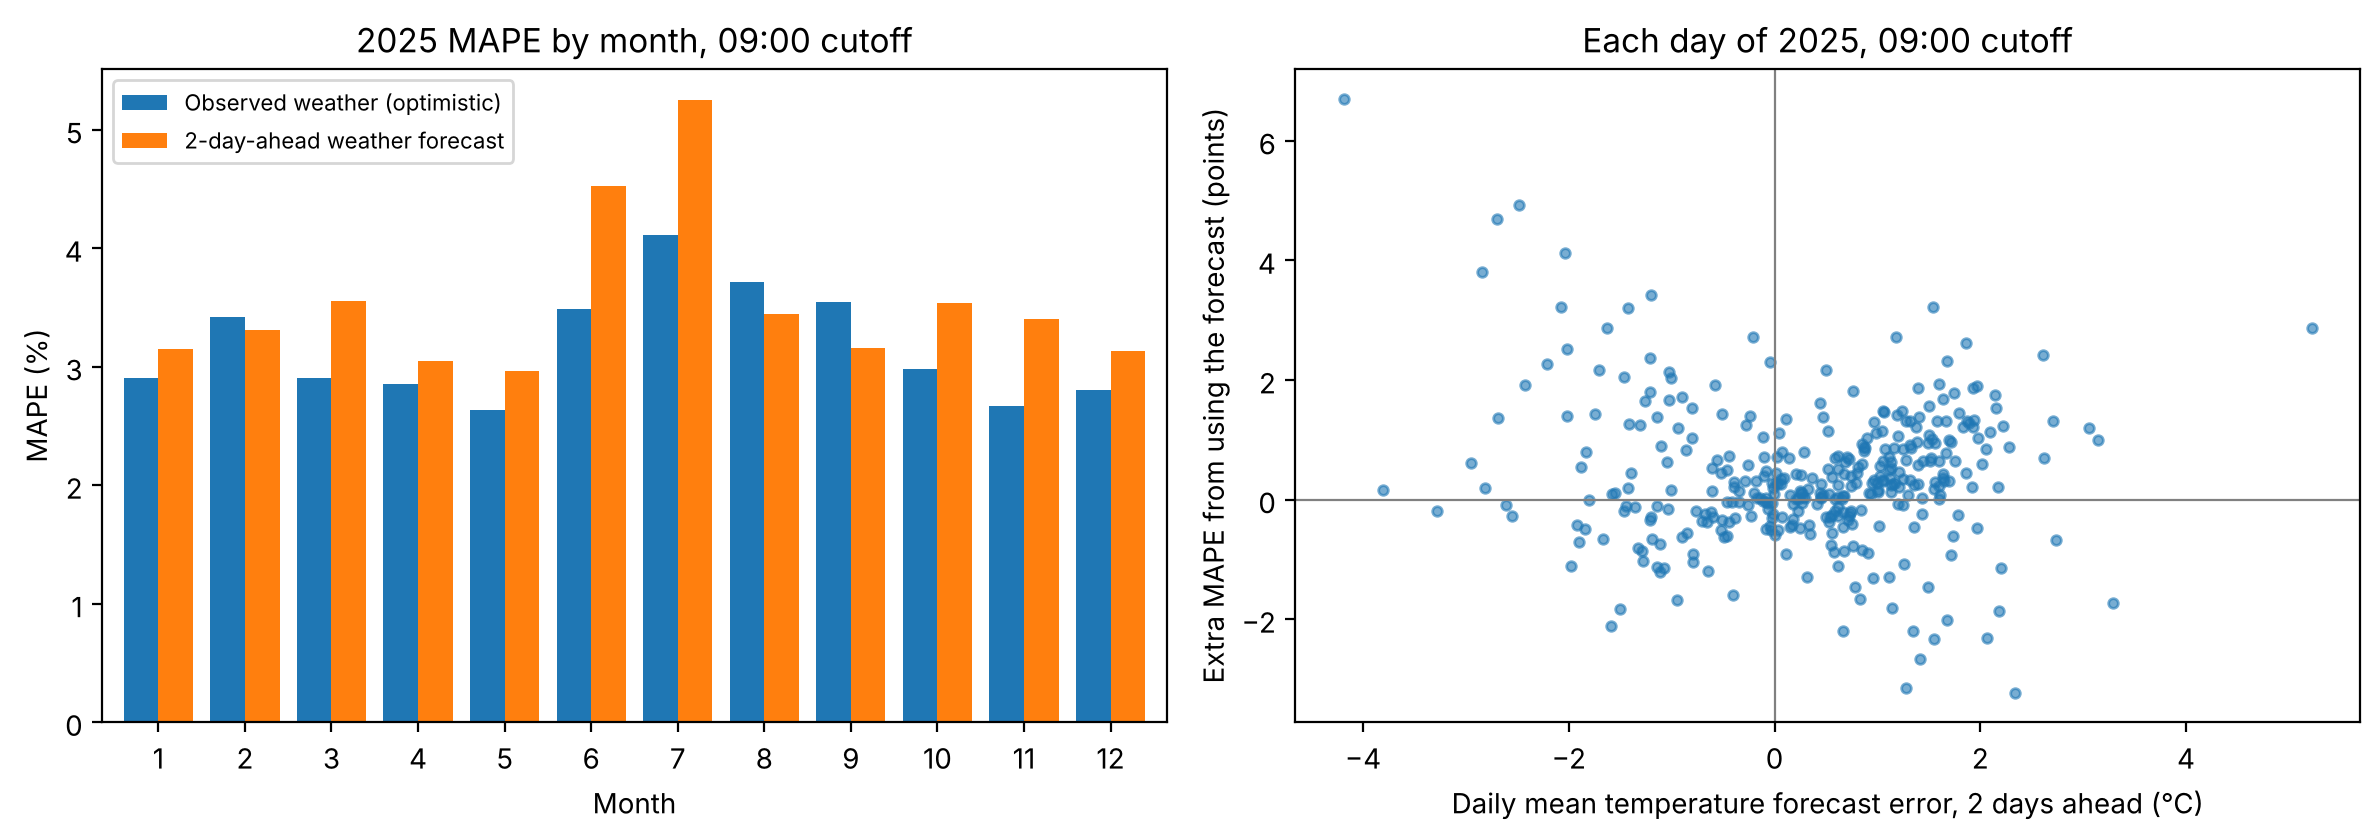

In [6]:
ape = pd.DataFrame({
    "Observed weather (optimistic)": (preds[(9, "observed")] - y).abs() / y * 100,
    "2-day-ahead weather forecast": (preds[(9, "2 day ahead")] - y).abs() / y * 100,
})
by_month = ape.groupby(ape.index.month).mean()
by_month["Extra error (points)"] = by_month.iloc[:, 1] - by_month.iloc[:, 0]

day_temp_err = (fc[2].loc["2025", "temp_c"] - obs25["temp_c"]).resample("D").mean()
day_extra = (ape.iloc[:, 1] - ape.iloc[:, 0]).resample("D").mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
by_month.iloc[:, :2].plot(kind="bar", ax=axes[0], width=0.8, rot=0)
axes[0].set(title="2025 MAPE by month, 09:00 cutoff", xlabel="Month", ylabel="MAPE (%)")
axes[0].legend(fontsize=8, loc="upper left")
axes[1].scatter(day_temp_err, day_extra, s=12, alpha=0.6)
axes[1].axhline(0, color="grey", lw=0.8); axes[1].axvline(0, color="grey", lw=0.8)
axes[1].set(title="Each day of 2025, 09:00 cutoff",
            xlabel="Daily mean temperature forecast error, 2 days ahead (°C)",
            ylabel="Extra MAPE from using the forecast (points)")
fig.tight_layout(); fig.savefig("figures/weather_forecast_effect_2025.png", dpi=130)
by_month.round(2).T

In [7]:
abs_err = day_temp_err.abs()
groups = pd.cut(abs_err, [0, 1, 2, 10], right=False, labels=["< 1 °C", "1-2 °C", ">= 2 °C"])
print("Extra MAPE (points) by size of the daily temperature forecast miss:")
print(day_extra.groupby(groups, observed=True).agg(["mean", "count"]).round(2))
print(f"\nCorrelation of |temperature miss| with extra MAPE: {abs_err.corr(day_extra):.2f}")
summer = day_temp_err.index.month.isin([6, 7, 8, 9])
print("\nExtra MAPE (points) when the daily mean temperature forecast was off by 1 °C or more:")
for season, m in [("Jun-Sep (cooling season)", summer), ("Oct-May", ~summer)]:
    e, x = day_temp_err[m], day_extra[m]
    print(f"  {season:<25} too cold: {(e <= -1).sum():>3} days, {x[e <= -1].mean():+.2f} | "
          f"too warm: {(e >= 1).sum():>3} days, {x[e >= 1].mean():+.2f}")

Extra MAPE (points) by size of the daily temperature forecast miss:
         mean  count
temp_c              
< 1 °C   0.12    178
1-2 °C   0.48    150
>= 2 °C  1.19     37

Correlation of |temperature miss| with extra MAPE: 0.28

Extra MAPE (points) when the daily mean temperature forecast was off by 1 °C or more:
  Jun-Sep (cooling season)  too cold:  25 days, +2.26 | too warm:  32 days, -0.50
  Oct-May                   too cold:  39 days, -0.02 | too warm:  91 days, +0.85


**Reading the chart and the table.**

- **Summer pays the most.** In June and July the extra error is about **1 point of MAPE** (June 3.49% → 4.53%, July 4.11% → 5.25%). In summer, demand reacts strongly to temperature (air conditioning), so a 1–2 °C miss in the forecast becomes a large MW miss.
- **Some months get slightly *better* with forecasts** (February, August, September). This is not because forecasts are better than reality: the model under-forecasts demand all year, and in August–September the 2-day-ahead forecasts were on average about 1 °C too warm, which pushed the demand forecast up and partly cancelled the under-forecast. Two errors in opposite directions.
- **Bigger weather misses, bigger demand misses.** On the 178 days where the daily mean temperature forecast was within 1 °C, using it costs only 0.12 MAPE points. On the 37 days where it was off by 2 °C or more, it costs 1.19 points. The correlation is modest (0.28) because the same temperature miss matters much more in July than in April.
- **The direction of the miss matters, and it flips with the season.** From June to September, a forecast at least 1 °C too cold costs 2.26 MAPE points (25 days), while a too-warm one slightly *reduces* the error (−0.50, 32 days). From October to May it is the other way round: too warm costs 0.85 points (91 days), too cold almost nothing (−0.02, 39 days). In both cases the costly miss is the one that makes demand look *lower* (a cooler summer day means less air conditioning, a milder winter day less heating), which adds to the model's existing under-forecast. A too-high weather signal partly cancels it. This is why the scatter plot is lopsided.

## 6. The highest-demand days

Notebook 06 found that the 20 highest-demand days of 2025 (all in summer) are the weak spot: the model under-forecasts every one of them. These are also the days where a temperature forecast error costs the most MW. We repeat the daily peak check on those 20 days.

In [8]:
day_peak = y.resample("D").max()
top20 = day_peak.nlargest(20).index
rows = {}
for key, label in [((9, "observed"), "09:00, observed weather"), ((9, "2 day ahead"), "09:00, 2-day-ahead forecast"),
                   ((0, "observed"), "Midnight, observed weather"), ((0, "1 day ahead"), "Midnight, 1-day-ahead forecast")]:
    p = preds[key].resample("D").max().loc[top20]
    rows[label] = {"Peak MAPE (%)": ((p - day_peak.loc[top20]).abs() / day_peak.loc[top20]).mean() * 100,
                   "Peak bias (MW)": (p - day_peak.loc[top20]).mean(),
                   "Days under-forecast": int((p < day_peak.loc[top20]).sum())}
lag48 = data[9].loc["2025", "lag_48"].resample("D").max().loc[top20]
rows["09:00, persistence (lag 48h)"] = {"Peak MAPE (%)": ((lag48 - day_peak.loc[top20]).abs() / day_peak.loc[top20]).mean() * 100,
                                         "Peak bias (MW)": (lag48 - day_peak.loc[top20]).mean(),
                                         "Days under-forecast": int((lag48 < day_peak.loc[top20]).sum())}
pd.DataFrame(rows).T.round(2)

,Peak MAPE (%),Peak bias (MW),Days under-forecast
"09:00, observed weather",5.83,-1379.75,20.0
"09:00, 2-day-ahead forecast",5.20,-1229.50,20.0
"Midnight, observed weather",4.75,-1122.06,20.0
"Midnight, 1-day-ahead forecast",4.91,-1158.72,20.0
"09:00, persistence (lag 48h)",6.12,-1088.50,15.0


**What this means.** On the 20 highest-demand days the model under-forecasts the peak on every day, with or without weather forecasts, by more than 1,100 MW on average. Weather forecasts do not change that picture much. At midnight, the 1-day-ahead forecasts were a little too cool on these days (−0.83 °C on average), and peak MAPE rises from 4.75% to 4.91%. At 09:00, the 2-day-ahead forecast made the peaks slightly *higher*, which happened to reduce the existing under-forecast (5.83% → 5.20%); that is luck, not skill. The real weak spot on these days is still the model itself: it does not reach the levels of a record-hot day, which is the next thing to fix (load growth and hot-day features).

## Takeaways

- **Fully realistic headline:** with a 09:00 EST deadline on the day before and real archived weather forecasts, LightGBM forecasts 2025 hourly Ontario demand with **3.54% MAPE (606 MW MAE)** and **3.71% daily-peak MAPE**. The 2.63% of notebook 03 had two optimistic assumptions built in (a midnight deadline and perfect weather knowledge); together they were worth about 0.9 MAPE points.
- **Still clearly useful:** the model cuts the error of the best fair naive forecast (6.52% MAPE) by 44%.
- **Weather forecast errors hurt most in summer**, when demand is most sensitive to temperature: about +1 MAPE point in June and July.
- **Caveats.** The models were trained on observed weather and only tested with forecasts; training on forecasts (possible from 2024 on) could help the model learn how much to trust them. The weather of D-1 after 09:00 (`temp_lag_24`, `temp_prev_day_mean`) is still observed in the 09:00 setup, a small remaining optimism. Weather is one point (Toronto) for all of Ontario.